In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

df = pd.read_parquet(
    PROJECT_ROOT
    / "data/processed/events.parquet"
)

df.head()

,event_id,timestamp,service,cpu_pct,memory_pct,failed_requests_5m,total_requests_5m,p95_latency_ms,incident_label,error_rate,no_traffic,hour_utc
0,EVT-000001,2026-01-01 08:00:00+00:00,payment-api,71.16,81.63,53,3681,569.0,0,0.014398,0,8
1,EVT-000002,2026-01-01 08:05:00+00:00,database-service,70.64,79.37,176,4467,1265.0,0,0.039400,0,8
2,EVT-000003,2026-01-01 08:10:00+00:00,user-service,98.88,43.13,7,138,1776.0,1,0.050725,0,8
3,EVT-000004,2026-01-01 08:15:00+00:00,auth-service,40.36,38.20,6,808,318.0,0,0.007426,0,8
4,EVT-000005,2026-01-01 08:20:00+00:00,payment-api,21.65,30.45,10,360,479.0,0,0.027778,0,8


In [2]:
print("Number of observations:", df.shape[0])
print("Number of columns:", df.shape[1])

df.info()

Number of observations: 1000
Number of columns: 12
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   event_id            1000 non-null   string             
 1   timestamp           1000 non-null   datetime64[us, UTC]
 2   service             1000 non-null   string             
 3   cpu_pct             1000 non-null   float64            
 4   memory_pct          1000 non-null   float64            
 5   failed_requests_5m  1000 non-null   int64              
 6   total_requests_5m   1000 non-null   int64              
 7   p95_latency_ms      1000 non-null   float64            
 8   incident_label      1000 non-null   int8               
 9   error_rate          1000 non-null   float64            
 10  no_traffic          1000 non-null   int8               
 11  hour_utc            1000 non-null   int8               


In [3]:
df.describe()

,cpu_pct,memory_pct,failed_requests_5m,total_requests_5m,p95_latency_ms,incident_label,error_rate,no_traffic,hour_utc
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.0000
mean,53.957810,56.846880,90.601000,985.461000,882.557000,0.300000,0.086816,0.050000,11.7280
std,26.227025,19.827908,199.308559,1071.030512,979.326695,0.458487,0.164995,0.218054,6.5752
min,5.380000,15.080000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000
25%,34.142500,40.875000,4.000000,333.000000,271.000000,0.000000,0.008897,0.000000,6.0000
50%,52.620000,56.970000,12.000000,664.000000,446.000000,0.000000,0.019788,0.000000,12.0000
75%,74.260000,70.920000,60.000000,1133.750000,1152.750000,1.000000,0.038822,0.000000,17.0000
max,99.990000,99.880000,1350.000000,4990.000000,3983.000000,1.000000,0.699482,1.000000,23.0000


In [4]:
print("Missing values per column:")

display(df.isna().sum())

print(
    "Duplicate event IDs:",
    df["event_id"].duplicated().sum()
)

Missing values per column:


event_id              0
timestamp             0
service               0
cpu_pct               0
memory_pct            0
failed_requests_5m    0
total_requests_5m     0
p95_latency_ms        0
incident_label        0
error_rate            0
no_traffic            0
hour_utc              0
dtype: int64

Duplicate event IDs: 0


incident_label
0    700
1    300
Name: count, dtype: int64


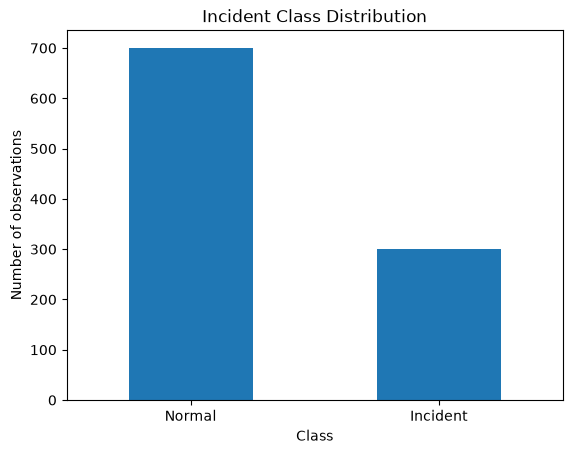

In [5]:
class_counts = (
    df["incident_label"]
    .value_counts()
    .sort_index()
)

print(class_counts)

class_counts.index = [
    "Normal",
    "Incident"
]

class_counts.plot(
    kind="bar",
    title="Incident Class Distribution"
)

plt.xlabel("Class")
plt.ylabel("Number of observations")
plt.xticks(rotation=0)

plt.show()

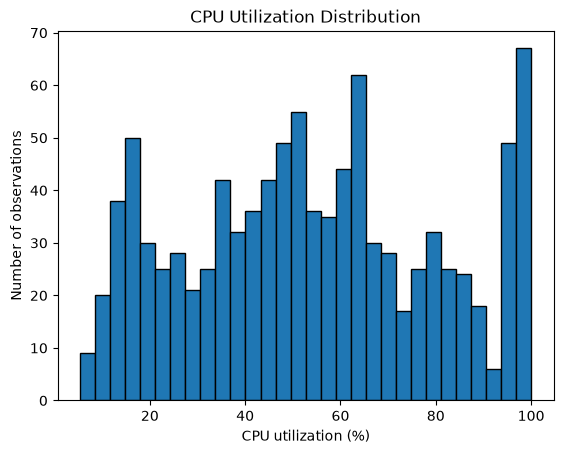

In [6]:
plt.hist(
    df["cpu_pct"],
    bins=30,
    edgecolor="black"
)

plt.title("CPU Utilization Distribution")
plt.xlabel("CPU utilization (%)")
plt.ylabel("Number of observations")

plt.show()

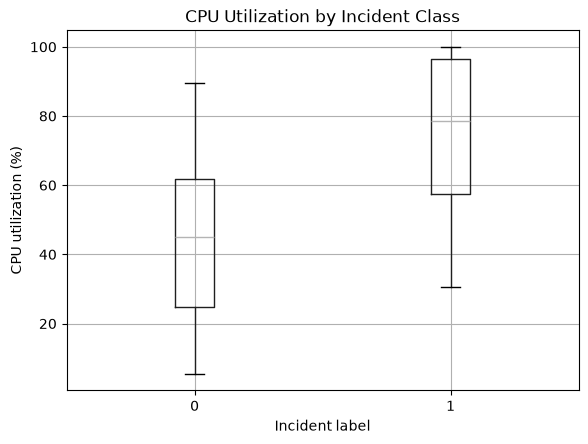

In [7]:
df.boxplot(
    column="cpu_pct",
    by="incident_label"
)

plt.title("CPU Utilization by Incident Class")
plt.suptitle("")
plt.xlabel("Incident label")
plt.ylabel("CPU utilization (%)")

plt.show()

In [8]:
features = [
    "cpu_pct",
    "memory_pct",
    "error_rate",
    "p95_latency_ms",
]

df.groupby("incident_label")[
    features
].mean()

,cpu_pct,memory_pct,error_rate,p95_latency_ms
incident_label,,,,
0,44.576314,51.435029,0.014257,395.325714
1,75.847967,69.474533,0.256120,2019.430000


In [9]:
numeric_features = [
    "cpu_pct",
    "memory_pct",
    "failed_requests_5m",
    "total_requests_5m",
    "p95_latency_ms",
    "error_rate",
    "no_traffic",
    "hour_utc",
    "incident_label",
]

correlation_matrix = df[
    numeric_features
].corr()

correlation_matrix.round(2)

,cpu_pct,memory_pct,failed_requests_5m,total_requests_5m,p95_latency_ms,error_rate,no_traffic,hour_utc,incident_label
cpu_pct,1.00,0.36,0.26,0.42,0.44,0.26,-0.35,0.00,0.55
memory_pct,0.36,1.00,0.24,0.30,0.40,0.27,-0.31,0.03,0.42
failed_requests_5m,0.26,0.24,1.00,0.21,0.75,0.86,-0.10,0.01,0.56
total_requests_5m,0.42,0.30,0.21,1.00,0.17,0.03,-0.21,0.02,-0.05
p95_latency_ms,0.44,0.40,0.75,0.17,1.00,0.84,-0.21,-0.03,0.76
error_rate,0.26,0.27,0.86,0.03,0.84,1.00,-0.12,-0.01,0.67
no_traffic,-0.35,-0.31,-0.10,-0.21,-0.21,-0.12,1.00,0.02,-0.15
hour_utc,0.00,0.03,0.01,0.02,-0.03,-0.01,0.02,1.00,-0.03
incident_label,0.55,0.42,0.56,-0.05,0.76,0.67,-0.15,-0.03,1.00


In [10]:
service_summary = df.groupby(
    "service"
).agg(
    total_events=("event_id", "count"),

    incident_count=("incident_label", "sum"),

    avg_cpu=("cpu_pct", "mean"),

    avg_memory=("memory_pct", "mean"),

    avg_latency=("p95_latency_ms", "mean"),

    avg_error_rate=("error_rate", "mean"),
)

service_summary["incident_rate"] = (
    service_summary["incident_count"]
    / service_summary["total_events"]
)

service_summary.round(3)

,total_events,incident_count,avg_cpu,avg_memory,avg_latency,avg_error_rate,incident_rate
service,,,,,,,
auth-service,187,54,53.759,55.819,877.444,0.083,0.289
database-service,223,68,53.456,56.476,822.673,0.089,0.305
notification-service,230,71,54.318,57.004,900.930,0.090,0.309
payment-api,175,49,52.237,56.490,865.474,0.084,0.280
user-service,185,58,55.944,58.474,953.227,0.088,0.314


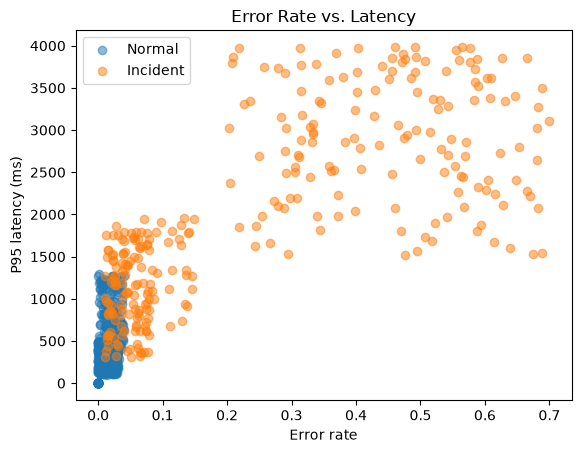

In [11]:
for label, name in [
    (0, "Normal"),
    (1, "Incident"),
]:

    subset = df[
        df["incident_label"] == label
    ]

    plt.scatter(
        subset["error_rate"],
        subset["p95_latency_ms"],
        alpha=0.5,
        label=name,
    )

plt.xlabel("Error rate")
plt.ylabel("P95 latency (ms)")
plt.title("Error Rate vs. Latency")
plt.legend()

plt.show()